
# 02 资金杠杆与公司级风控

> **本章要解决的问题**：自己的 100 万，最多能开多大的仓？3 倍杠杆下，标的多跌多少会触发强平？同样的策略，杠杆 1 倍和 5 倍的破产概率差多少？公司账户要不要设一条“越线就停手”的 kill switch？

## 本章导读

“一人公司”与“个人账户”在风控上的最大区别是：公司资金要**先活下来，再谈收益**。个人可以重仓搏一把，公司账户一旦爆掉，连主体、数据和客户关系都跟着受损。

本章把公司级风控拆成五件事：

1. **资金与杠杆**：权益、名义敞口、保证金、强平线之间的关系；
2. **回撤与破产**：怎样度量“最坏跌了多少”，以及破产概率怎么看；
3. **资金分配**：多个策略之间按什么分钱；
4. **kill switch**：什么条件触发、触发后做什么；
5. **压力测试**：极端情景下不同杠杆的后果。

> **声明**：本章的保证金率、涨跌停、强平规则均为**教学示例，非专业意见**。真实规则以交易所、期货公司和券商当期规定为准。

### 学习目标

- 给定权益、名义敞口和保证金率，能算出杠杆倍数、保证金占用和“跌多少会触及维持保证金”。
- 给定日收益分布和杠杆，能用蒙特卡洛模拟一年权益路径，并估计破产概率与最大回撤分布。
- 给定若干策略的预期收益、波动率和相关性，能比较等权、波动率倒数、风险预算三种资金分配方案。
- 给定公司风险偏好，能写出至少三条 kill switch 规则，并说明触发后的动作。
- 给定压力测试情景（单日大跌、连续下跌、跳空），能算出不同杠杆下的权益损失与强平判断。
- 能解释“高杠杆 + 高胜率”为什么可能同时意味着高破产概率。

### 先修

第 30 章（组合与最优化）、第 35 章（凯利公式与仓位管理）、第 36 章（蒙特卡洛模拟与方差缩减）；会 numpy 与 pandas 的基础操作。

## 在量化研究中的位置

- **谁用**：一人公司创始人、交易负责人、资金方、风控负责人。
- **输入**：自有资金、策略收益与回撤、杠杆上限、保证金率、强平规则、历史极端行情。
- **输出**：杠杆上限、保证金与强平表、破产概率估计、资金分配方案、kill switch 规则、压力测试报告。
- **在流程的哪一步**：在“策略能赚钱”之后、“放大规模”之前；它决定公司能承受多大的坏运气。
- **失败模式**：只看收益不看回撤、杠杆按“平均波动”设计、kill switch 从不触发或天天触发、压力测试只测温和情景。
- **最小工作流**：算杠杆与强平线 → 模拟破产概率 → 分配资金 → 设 kill switch → 跑压力测试 → 定期复核。

### 环境准备



In [1]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams["font.sans-serif"] = ["Microsoft YaHei", "SimHei", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False
pd.set_option("display.width", 120)
print("numpy", np.__version__, "| pandas", pd.__version__)
print("本章保证金率与强平规则均为教学示例，非专业意见")


numpy 2.4.4 | pandas 3.0.2
本章保证金率与强平规则均为教学示例，非专业意见



## 1. 资金、杠杆与保证金

### 1.1 三个数：权益、名义敞口、杠杆

把公司账户想成一张资产负债表：

- **权益（equity）**：账户里真正属于你的钱 = 现金 + 浮盈；
- **名义敞口（notional）**：你持有的合约面值合计；
- **杠杆（leverage）**：$L=\dfrac{\text{名义敞口}}{\text{权益}}$。

杠杆不是“借了多少钱”，而是“用多少本钱撬动了多大的名义仓位”。做期货不需要全额买入，只要交保证金，所以现货账户 1 倍、期货账户很容易到 5–10 倍。

### 1.2 保证金与强平线

期货/期权卖方要交保证金。设保证金率为 $m$（教学示例 12%），维持保证金率为 $m_{\text{maint}}$（示例 10%）：

- 开仓保证金 = 名义敞口 × $m$；
- 当权益跌到维持保证金以下，账户会被要求追加保证金，否则强平。

假设满仓操作（保证金刚好用完），从开仓到触及维持保证金，标的最多能跌：

$$\text{可承受跌幅}=\frac{1}{L}-m_{\text{maint}}.$$

这个式子是本章最重要的一条：**杠杆越高，能扛的跌幅越小**。3 倍杠杆只能扛约 23%，5 倍只剩 10%，8 倍只有 2.5%。

### 1.3 手算

权益 100 万，保证金率 12%，维持保证金率 10%：

- 杠杆 1 倍：名义 100 万，占用保证金 12 万，剩余 88 万；可承受跌幅 $1/1-0.10=90\%$；
- 杠杆 3 倍：名义 300 万，占用 36 万，可承受 $1/3-0.10\approx23.3\%$；
- 杠杆 5 倍：名义 500 万，占用 60 万，可承受 $1/5-0.10=10\%$。

注意：这是“满仓 + 无融资成本 + 无追加保证金”的简化，真实强平还受涨跌停、流动性、保证金率上调影响，实际能扛的跌幅往往更小。

### 1.4 代码：杠杆与强平线



In [2]:

equity = 1_000_000.0
margin_rate = 0.12
maint_rate = 0.10
rows = []
for lev in [1, 2, 3, 5, 8]:
    notional = equity * lev
    margin = notional * margin_rate
    if margin > equity:
        continue
    buffer = equity - margin
    forced_drop = 1.0 / lev - maint_rate
    rows.append(
        {
            "杠杆": lev,
            "名义敞口": notional,
            "保证金占用": margin,
            "剩余权益": buffer,
            "维持保证金": notional * maint_rate,
            "可承受跌幅%": round(forced_drop * 100, 2),
        }
    )
lev_table = pd.DataFrame(rows)
print(lev_table.to_string(index=False))
print("保证金率 12% 时理论上限杠杆 =", round(1 / margin_rate, 2), "倍")


 杠杆      名义敞口    保证金占用     剩余权益    维持保证金  可承受跌幅%
  1 1000000.0 120000.0 880000.0 100000.0   90.00
  2 2000000.0 240000.0 760000.0 200000.0   40.00
  3 3000000.0 360000.0 640000.0 300000.0   23.33
  5 5000000.0 600000.0 400000.0 500000.0   10.00
  8 8000000.0 960000.0  40000.0 800000.0    2.50
保证金率 12% 时理论上限杠杆 = 8.33 倍



**读数与应用**：5 倍杠杆的可承受跌幅只有 10%，而商品期货单日 3%–5% 的波动并不罕见，连续两天反向就可能接近强平。**杠杆不是按“平均波动”设计的，是按“最坏情况”设计的。** 常见错误：用保证金率算杠杆却忘了维持保证金、把“可承受跌幅”当“止损线”、忽略交易所临时上调保证金。

### 1.5 资金成本与融资

杠杆还有一项常被忽略的成本：资金成本。融资买入要付利息，期货保证金虽不直接计息，但占用的钱失去了无风险收益。粗略可写成：

$$\text{年化资金成本}\approx L\cdot r_{\text{借}}+(1-\text{保证金效率})\cdot r_f.$$

教学示例：融资利率 6%、杠杆 3 倍、其中 2 倍是借来的，年化资金成本约 4%；策略年化 8% 时，真实超额只剩 4%。**杠杆放大收益之前，先扣掉资金成本。**

## 2. 回撤与破产概率

### 2.1 最大回撤

最大回撤（MDD）回答“从最高点跌下来最多跌了多少”：

$$\text{MDD}=\max_t\left(1-\frac{E_t}{\max_{s\le t}E_s}\right).$$

它有三个维度：**深度**（跌多少）、**持续期**（多久没创新高）、**恢复期**（多久涨回去）。只看深度会低估痛苦程度。

### 2.2 破产与“接近破产”

严格破产是权益 ≤ 0；实务上更常见的是**触及强平**或**回撤超过公司容忍线**。这两件事要分开统计：

- 破产概率：一年内权益是否曾 ≤ 0；
- 强平/熔断概率：权益是否曾跌破维持保证金或公司回撤红线。

### 2.3 蒙特卡洛：一年权益路径

用几何布朗运动的简化版：日收益 $r_t\sim N(\mu/252,\ \sigma/\sqrt{252})$，杠杆后的权益收益为 $L\cdot r_t$（忽略融资成本与调仓）。模拟 5,000 条路径、250 个交易日，看不同杠杆下的破产概率与回撤分布。



 杠杆  强平概率%  破产概率%  年收益中位数%  年收益5%分位%  回撤中位数%  回撤>30%概率%
  1   0.00    0.0     7.05    -16.53   12.83       1.22
  2   0.00    0.0    12.13    -31.94   24.51      30.14
  3   0.48    0.0    14.89    -45.82   35.14      66.88
  5  29.72    0.0    12.44    -67.95   53.24      96.80
  8  84.68    0.0    -8.06    -87.86   73.49     100.00


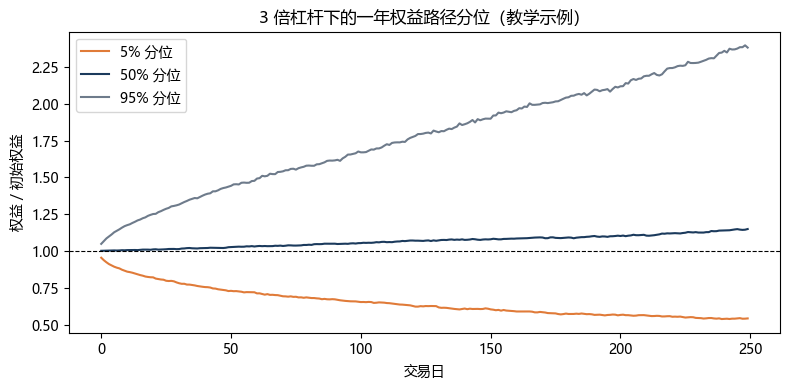

In [3]:

rng = np.random.default_rng(20240101)
mu_annual, sigma_annual = 0.08, 0.15
days, n_paths = 250, 5000
daily_ret = rng.normal(mu_annual / 252, sigma_annual / np.sqrt(252), size=(n_paths, days))

rows = []
for lev in [1, 2, 3, 5, 8]:
    ep = np.cumprod(1 + lev * daily_ret, axis=1)
    dd = 1 - ep / np.maximum.accumulate(ep, axis=1)
    mdd = dd.max(axis=1)
    terminal = ep[:, -1] - 1
    forced = (ep.min(axis=1) <= lev * maint_rate).mean()
    rows.append(
        {
            "杠杆": lev,
            "强平概率%": round(forced * 100, 2),
            "破产概率%": round((ep.min(axis=1) <= 0).mean() * 100, 2),
            "年收益中位数%": round(np.median(terminal) * 100, 2),
            "年收益5%分位%": round(np.percentile(terminal, 5) * 100, 2),
            "回撤中位数%": round(np.median(mdd) * 100, 2),
            "回撤>30%概率%": round((mdd > 0.30).mean() * 100, 2),
        }
    )
risk_table = pd.DataFrame(rows)
print(risk_table.to_string(index=False))

ep3 = np.cumprod(1 + 3 * daily_ret, axis=1)
plt.figure(figsize=(8, 4))
for q, color in [(5, "#E07B39"), (50, "#1B3A5C"), (95, "#6E7B8B")]:
    plt.plot(np.percentile(ep3, q, axis=0), color=color, label=f"{q}% 分位")
plt.axhline(1.0, color="black", linewidth=0.8, linestyle="--")
plt.title("3 倍杠杆下的一年权益路径分位（教学示例）")
plt.xlabel("交易日")
plt.ylabel("权益 / 初始权益")
plt.legend()
plt.tight_layout()
plt.show()



**读数与应用**：1–2 倍杠杆一年内触及强平的概率接近 0，3 倍约 0.5%，5 倍约三成，8 倍超过八成；但真正亏到零的概率都是 0——正态假设掩盖了跳空风险。**高杠杆的真实代价是尾部，不是均值。** 常见错误：只看年化收益、用正态分布低估跳空、忽略强平后无法“等反弹”。

### 2.4 回撤、凯利与破产

第 35 章讲过凯利公式：最优仓位与“优势/赔率”有关。凯利给的是**长期增长最快**的仓位，不是“最安全”的仓位；而且它对参数估计误差非常敏感——把胜率估高 5 个百分点，凯利仓位可能翻倍。

一人公司的做法通常是“半凯利甚至四分之一凯利”：用凯利算出一个上限，再按回撤容忍度打折。原因很实际：凯利假设你能承受过程中的巨大回撤，而公司账户还要付工资、数据和税。

## 3. 策略组合与资金分配

### 3.1 三个策略

假设公司有三个策略（教学示例）：

| 策略 | 年化收益 | 年化波动 | 相关系数 |
|---|---:|---:|---|
| A 低频反转 | 8% | 10% | 与 B 0.2、与 C 0.1 |
| B 趋势跟踪 | 12% | 18% | 与 C 0.3 |
| C 期权卖方 | 15% | 25% | — |

### 3.2 三种分钱方式

1. **等权**：每个策略 1/3，简单但风险集中；
2. **波动率倒数**：权重 $\propto 1/\sigma_i$，让每个策略的波动贡献相近；
3. **风险预算**：给定目标风险占比（例如 50%/30%/20%），迭代求解使每个策略的风险贡献 $RC_i$ 接近目标。

风险贡献用欧拉分解：$RC_i=\dfrac{w_i(Sw)_i}{w^TSw}$，$\sum_i RC_i=1$。

### 3.3 代码：三种方案对比



In [4]:

vols = np.array([0.10, 0.18, 0.25])
corr = np.array([[1.0, 0.2, 0.1], [0.2, 1.0, 0.3], [0.1, 0.3, 1.0]])
cov = np.outer(vols, vols) * corr
mu = np.array([0.08, 0.12, 0.15])


def risk_contrib(w, cov):
    port_var = w @ cov @ w
    return w * (cov @ w) / port_var


def report(name, w):
    port_vol = np.sqrt(w @ cov @ w)
    return {
        "方案": name,
        "权重A": round(w[0], 3),
        "权重B": round(w[1], 3),
        "权重C": round(w[2], 3),
        "年化收益%": round(w @ mu * 100, 2),
        "年化波动%": round(port_vol * 100, 2),
        "风险收益比": round((w @ mu) / port_vol, 2),
    }


w_equal = np.ones(3) / 3
w_invvol = (1 / vols) / (1 / vols).sum()
target_rc = np.array([0.5, 0.3, 0.2])
w_erc = w_invvol.copy()
for _ in range(500):
    w_erc = w_erc * (target_rc / risk_contrib(w_erc, cov))
    w_erc = w_erc / w_erc.sum()

alloc = pd.DataFrame([report("等权", w_equal), report("波动率倒数", w_invvol), report("风险预算", w_erc)])
print(alloc.to_string(index=False))
print("风险预算方案的风险贡献占比:", risk_contrib(w_erc, cov).round(3))


   方案   权重A   权重B   权重C  年化收益%  年化波动%  风险收益比
   等权 0.333 0.333 0.333  11.67  12.65   0.92
波动率倒数 0.511 0.284 0.205  10.57  10.48   1.01
 风险预算 0.625 0.237 0.139   9.92   9.64   1.03
风险预算方案的风险贡献占比: [0.5 0.3 0.2]



**读数与应用**：等权方案里，波动最大的 C 策略贡献了大部分风险；风险预算方案把 A 的权重提高到约六成（0.625），组合波动从 12.65% 降到 9.64%，收益从 11.67% 降到 9.92%。**没有免费午餐：降波动通常要牺牲一点收益。** 常见错误：按“历史收益”分配资金、把权重当风险贡献、忽略策略相关性在危机时会上升。

### 3.4 资金分配的实操约束

公式算出来的权重还要过四道现实约束：

1. **最小手数**：资金小的时候，0.3 手的权重只能取 0 或 1 手，实际权重会偏离；
2. **保证金占用**：多策略共用账户，保证金要加总，不能各自按满仓算；
3. **相关性漂移**：危机时相关性上升，历史协方差低估组合风险；
4. **容量**：策略规模越大，滑点和冲击成本越高，权重不能只看收益率。

所以资金分配不是一个公式算完，而是“公式给初值 → 按约束取整 → 压力测试复核”。

## 4. 公司级 kill switch

### 4.1 规则长什么样

kill switch 不是“亏钱就停”，而是一组事先写死的规则，例如（教学示例）：

| 规则 | 阈值 | 触发后动作 |
|---|---|---|
| 单日亏损 | ≥ 权益的 3% | 当日停止开新仓 |
| 回撤 | 自高点回撤 ≥ 15% | 降杠杆到 1 倍，人工复核 |
| 连续亏损 | 连续 5 个交易日亏损 | 暂停策略，检查数据与模型 |
| 波动异常 | 组合波动 > 目标 2 倍 | 减仓，重估保证金额度 |

### 4.2 设计原则

1. **阈值来自压力测试**，不是拍脑袋；
2. **动作要分级**：停新仓、降杠杆、全平、人工复核；
3. **可执行**：触发后谁执行、多久内执行、如何记录；
4. **可复核**：每次触发都要复盘，区分“规则对了”和“市场噪声”。

两个常见误区：一是把 kill switch 当“亏损上限”，以为设了就不会亏——它只限制继续亏损的规模；二是行情剧烈时才临时决定要不要停，结果往往犹豫不决。正确做法是把它当成“预先承诺”：规则替你按下按钮，执行人只负责执行和记录。

### 4.3 代码：熔断前后的对比

用 3 倍杠杆的模拟路径比较两种做法：一直持有 vs 单日亏损 ≥3% 后清仓并停止。看中位数和 5% 分位终值。



In [5]:

n_switch = 2000
rng2 = np.random.default_rng(20240202)
ret_switch = rng2.normal(mu_annual / 252, sigma_annual / np.sqrt(252), size=(n_switch, days))


def run_with_switch(lev, use_switch):
    """触发条件：单日亏损 >=6%，或自高点回撤 >=25%；触发后停止交易。"""
    equity = np.ones(n_switch)
    peak = np.ones(n_switch)
    active = np.ones(n_switch, dtype=bool)
    for t in range(days):
        step = lev * ret_switch[:, t]
        equity = np.where(active, equity * (1 + step), equity)
        peak = np.maximum(peak, equity)
        if use_switch:
            hit = active & ((step <= -0.06) | (equity / peak - 1 <= -0.25))
            active = active & ~hit
    return equity, ~active


hold = np.cumprod(1 + 2 * ret_switch, axis=1)[:, -1]
switched, stopped = run_with_switch(2, True)
compare = pd.DataFrame(
    {
        "方案": ["2倍一直持有", "2倍+熔断"],
        "中位终值": [round(np.median(hold), 3), round(np.median(switched), 3)],
        "5%分位终值": [round(np.percentile(hold, 5), 3), round(np.percentile(switched, 5), 3)],
        "触发比例%": [0.0, round(stopped.mean() * 100, 2)],
    }
)
print(compare.to_string(index=False))


    方案  中位终值  5%分位终值  触发比例%
2倍一直持有 1.100   0.678    0.0
 2倍+熔断 1.027   0.752   55.9



**读数与应用**：2 倍杠杆下约 56% 的年份会触发熔断；触发后 5% 分位终值从 0.68 升到 0.75，但中位数从 1.10 降到 1.03——**熔断是用收益换生存，不是提高收益**。常见错误：阈值设得太松（从不触发）或太紧（天天触发）、触发后没有人工复核、只回测不实盘演练。

### 4.4 分级动作与执行清单

kill switch 触发后做什么，要提前写死，避免临场犹豫：

| 级别 | 触发条件（示例） | 动作 | 谁执行 |
|---|---|---|---|
| 黄 | 单日亏损 2% | 停止开新仓，检查数据 | 交易员 |
| 橙 | 回撤 10% | 杠杆减半，复核策略 | 负责人 |
| 红 | 回撤 15% 或连亏 5 天 | 全部平仓，暂停一周 | 负责人 + 外部顾问 |

关键是“谁执行、多久内执行、如何记录”。只写“触发后停止交易”而不写执行人，实盘时往往没人按下按钮。

### 4.5 kill switch 的演练

规则写完不等于能用。至少做三次演练：一次在模拟盘上验证触发链路（谁收到通知、多久平仓），一次在历史极端行情上回放（触发点是否合理），一次在实盘小资金上验证（手续费与滑点是否可接受）。演练记录本身也是留痕的一部分。

## 5. 压力测试

### 5.1 三种情景

压力测试不看“正常波动”，看“如果今天发生最坏情况会怎样”。至少覆盖：

1. 单日大跌：例如 -8%；
2. 连续下跌：例如 5 个交易日累计 -15%；
3. 跳空/流动性冲击：例如开盘直接跳空 -10%，无法止损。

### 5.2 用“可承受跌幅”判断强平

结合第 1 节的公式：杠杆 $L$ 下可承受跌幅为 $1/L-m_{\text{maint}}$。若情景跌幅超过它，就按“强平”处理。

### 5.3 代码：情景 × 杠杆



In [6]:

scenarios = {
    "单日-8%": -0.08,
    "连续5日累计-15%": -0.15,
    "跳空-10%": -0.10,
    "单日-5%": -0.05,
}
levs = [1, 2, 3, 5]
rows = []
for lev in levs:
    row = {"杠杆": lev}
    for name, shock in scenarios.items():
        equity_after = 1 + lev * shock
        row[name] = f"{equity_after * 100:.1f}%"
        if equity_after - 1 <= -(1 / lev - maint_rate):
            row[name] += "（强平）"
    rows.append(row)
stress = pd.DataFrame(rows)
print(stress.to_string(index=False))
print("可承受跌幅：", {lev: f"{(1 / lev - maint_rate) * 100:.1f}%" for lev in levs})


 杠杆     单日-8% 连续5日累计-15%    跳空-10%     单日-5%
  1     92.0%      85.0%     90.0%     95.0%
  2     84.0%      70.0%     80.0%     90.0%
  3 76.0%（强平）  55.0%（强平） 70.0%（强平）     85.0%
  5 60.0%（强平）  25.0%（强平） 50.0%（强平） 75.0%（强平）
可承受跌幅： {1: '90.0%', 2: '40.0%', 3: '23.3%', 5: '10.0%'}



**读数与应用**：3 倍杠杆遇到“连续 5 日 -15%”会损失 45%，5 倍杠杆同日情景直接强平。**压力测试的价值是提前知道“哪一档杠杆不能碰”，而不是预测哪天会发生。** 常见错误：只测温和情景、忽略跳空导致止损失效、用完压力测试就锁进抽屉。

### 5.4 压力测试的组织方式

压力测试不是跑一次就完，而是定期做、换情景做：

1. 每季度做一次常规情景（单日 -5%、-8%）；
2. 每次提高杠杆前做一次极端情景（跳空 -10%、连续 -15%）；
3. 每年复盘一次真实发生的极端行情，检查当时是否扛得住；
4. 把结论写成“杠杆上限表”，贴在交易台前，而不是只存在报告里。

压力测试的目标不是预测，而是**提前决定“到哪一步必须停”**。

## 本章小结

### 一张表

| 概念 | 公式/做法 | 用途 |
|---|---|---|
| 杠杆 | $L=\text{名义敞口}/\text{权益}$ | 放大收益与风险 |
| 可承受跌幅 | $1/L-m_{\text{maint}}$ | 强平线估算 |
| 最大回撤 | $\max_t(1-E_t/\max E)$ | 度量痛苦程度 |
| 破产概率 | 权益 ≤ 0 的路径占比 | 尾部风险 |
| 资金分配 | 等权/波动率倒数/风险预算 | 多策略分钱 |
| kill switch | 日亏/回撤/连亏阈值 | 公司级刹车 |
| 压力测试 | 情景 × 杠杆 | 提前看后果 |

### 八句话

1. 杠杆按最坏情况设计，不按平均波动。
2. 可承受跌幅 = 1/杠杆 − 维持保证金率。
3. 回撤要看深度、持续期、恢复期。
4. 杠杆放大的是尾部，不只是均值。
5. 权重不等于风险贡献。
6. 危机时策略相关性会上升。
7. kill switch 是刹车，不是油门。
8. 压力测试的意义是提前知道哪档杠杆不能碰。

## 本章习题

**1.** 权益 200 万、名义敞口 600 万、保证金率 12%，杠杆是多少？开仓保证金多少？

**2.** 维持保证金率 10%，杠杆 4 倍，可承受跌幅是多少？

**3.** 为什么高杠杆下“回撤 20%”可能已经意味着接近强平？

**4.** 三个策略波动率 8%/15%/30%，按波动率倒数分配，权重分别是多少？

**5.** 风险贡献 RC 之和为什么等于 1？

**6.** kill switch 的阈值应该从哪里来？为什么不能拍脑袋？

**7.** 压力测试至少应覆盖哪三类情景？

**8.** 为什么“熔断后中位收益下降”不一定是坏事？

<details><summary>参考答案</summary>

**1.** 杠杆 600/200 = 3 倍；保证金 = 600×12% = 72 万。

**2.** 1/4 − 0.10 = 15%。

**3.** 因为可承受跌幅约 1/L − 维持保证金率，杠杆越高该值越小；20% 回撤可能已经接近甚至超过可承受跌幅（教学示例，实际以规则为准）。

**4.** 权重 ∝ 1/波动率：1/0.08=12.5、1/0.15≈6.67、1/0.30≈3.33，合计 22.5，权重约 55.6%/29.6%/14.8%。

**5.** 欧拉分解把组合方差按各资产贡献拆分，每项 $w_i(Sw)_i/(w^TSw)$ 相加即为 $w^TSw/w^TSw=1$。

**6.** 从压力测试与历史极端情景来；拍脑袋的阈值要么从不触发、要么在正常波动中频繁误杀。

**7.** 单日大跌、连续下跌、跳空/流动性冲击（可再加波动率突变）。

**8.** 因为熔断用一部分中位收益换尾部生存，先活下来才有复利；但要检查是否误触发过多。

</details>

---

## 参考资料

- Hull, J. C. *Risk Management and Financial Institutions*（VaR、压力测试与杠杆）。
- 各期货交易所风险控制管理办法与保证金制度（以最新规则为准）。
- 第 30 章（组合与最优化）、第 35 章（凯利公式）、第 36 章（蒙特卡洛与方差缩减）。
